In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

from ppghr.windows import load_all_windows
from ppghr.features import spectral_features
from ppghr.baseline import estimate_hr_fft
from ppghr.evaluate import loso_predict, per_subject_mae
from ppghr.metrics import mae

In [2]:
data = load_all_windows()
X = spectral_features(data)
y = data["hr"]
subjects = data["subject"]
print("X:", X.shape, "  y:", y.shape)

X: (64697, 228)   y: (64697,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train, y_train)
print(f"Random split MAE: {mae(model.predict(X_test), y_test):.1f} bpm")

Random split MAE: 8.1 bpm


In [4]:
predictions = loso_predict(lambda: KNeighborsRegressor(n_neighbors=5), X, y, subjects)
per_subject, average = per_subject_mae(predictions, y, subjects)
print(f"Leave-one-subject-out MAE: {average:.1f} bpm")

Leave-one-subject-out MAE: 13.1 bpm


FFT baseline: 17.9 bpm


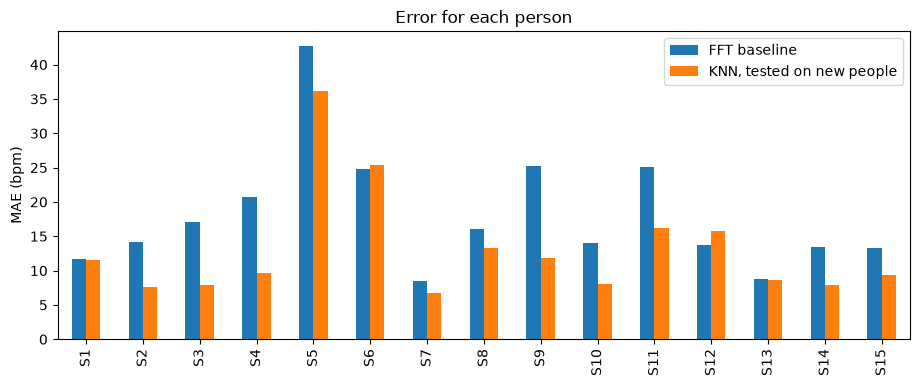

,FFT baseline,"KNN, tested on new people"
S1,11.6,11.5
S2,14.1,7.6
S3,17.0,7.9
S4,20.7,9.6
S5,42.7,36.2
S6,24.8,25.4
S7,8.5,6.7
S8,16.0,13.3
S9,25.2,11.9
S10,14.0,8.1


In [5]:
baseline_per_subject, baseline_average = per_subject_mae(estimate_hr_fft(data["ppg"]), y, subjects)
print(f"FFT baseline: {baseline_average:.1f} bpm")

table = pd.DataFrame({"FFT baseline": baseline_per_subject,
                      "KNN, tested on new people": per_subject})
table.index = [f"S{s}" for s in table.index]
table.plot.bar(figsize=(11, 4))
plt.ylabel("MAE (bpm)")
plt.title("Error for each person")
plt.show()
table.round(1)